# 03 · Modelo nodal y equivalente determinista de la instancia reducida

En este notebook se escribe el modelo de optimización sobre el árbol. En cada nodo se decide cuánto invertir en cada activo, la riqueza que llega a un nodo tiene que ser exactamente la que dejaron las inversiones de su padre, y al final se compara cada resultado con la meta. Se muestran las matrices que conectan cada nodo con su padre, el problema de un nodo final junto con su dual, y se comprueba que los multiplicadores que entrega el solver tienen el signo que necesita el L-shaped anidado. También se explica por qué el modelo nunca usa información del futuro y por qué cualquier decisión deja siempre un camino factible. Luego se resuelve el problema completo de una versión reducida del árbol, con solo dos combinaciones posibles por trimestre, cuyo óptimo servirá para comprobar en el notebook 04 que el L-shaped está bien implementado. Al final se resuelve también el problema completo del árbol de ocho combinaciones, solo como referencia adiciona. La solución oficial del caso completo es la que entrega el L-shaped. 

In [1]:
import hashlib
import json
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sp
from scipy.optimize import linprog
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)

## 1. Carga de parámetros y del árbol

Se verifican los hashes de `calibration_parameters.json` y de `scenario_tree_nodes.csv`, y que el árbol se haya construido con esos mismos parámetros.

In [2]:
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PARAMS_DIR = ROOT / "results" / "parameters"
TREE_DIR = ROOT / "results" / "tree"
REDUCED_DIR = ROOT / "results" / "reduced"
FULL_DE_DIR = ROOT / "results" / "full_de"
FIGURES_DIR = ROOT / "results" / "figures"
for d in [REDUCED_DIR, FULL_DE_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def sha256_of(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

params_path = PARAMS_DIR / "calibration_parameters.json"
params_hash = (PARAMS_DIR / "calibration_parameters.sha256").read_text().strip()
assert sha256_of(params_path) == params_hash, "Los parámetros congelados cambiaron."
params = json.loads(params_path.read_text(encoding="utf-8"))

tree_meta = json.loads((TREE_DIR / "tree_metadata.json").read_text(encoding="utf-8"))
tree_csv = ROOT / tree_meta["csv_file"]
assert sha256_of(tree_csv) == tree_meta["csv_sha256"], "El árbol exportado cambió."
assert tree_meta["calibration_parameters_sha256"] == params_hash, "El árbol se construyó con otros parámetros."

TICKERS = params["tickers"]
N_ASSETS = len(TICKERS)
B_CAP, M_GOAL, LAM = params["b"], params["M"], params["lambda"]
ACTIVE_STATES = params["active_states"]
Q_HAT = {u: params["states"][u]["q_hat"] for u in ACTIVE_STATES}
R_HAT = {u: np.array([params["states"][u]["R_hat"][t] for t in TICKERS]) for u in ACTIVE_STATES}
H = 4

full_tree = pd.read_csv(tree_csv, keep_default_na=False, na_values=[""])
print(f"b = {B_CAP}, M = {M_GOAL}, λ = {LAM} (miles de USD)")
print(f"Árbol completo: {len(full_tree)} nodos; parámetros y árbol verificados.")

b = 100.0, M = 106.0, λ = 4.0 (miles de USD)
Árbol completo: 585 nodos; parámetros y árbol verificados.


## 2. Constructores del árbol y del equivalente determinista

Las funciones son generales: reciben una lista de estados, sus probabilidades y sus factores, y sirven igual para el árbol completo y para el reducido. Para el árbol completo se comprueba que el resultado coincide con el exportado por el notebook 02.

**Orden de las variables:** Se recorren los nodos en el orden `node_id` (etapa y luego $k$). Cada nodo de decisión aporta $(x^t_{\text{SPY},k}, x^t_{\text{LQD},k}, x^t_{\text{GLD},k})$ y cada hoja aporta $(y^4_k, w^4_k)$.

**Orden de las igualdades:** Una fila por nodo, en el mismo orden: la fila del nodo $(t,k)$ es su balance $T_{t-1,k}\,x^{t-1}_{a(k)} + W_t\,x^t_k = h^t_k$.

In [3]:
def build_tree(states, q, Rmap, H=4):
    # Árbol con la misma indexación del notebook 02: hijo l = S(k-1) + s + 1.
    S = len(states)
    rows, frontier, nid = [], [(1, ())], 0
    for t in range(1, H + 1):
        nxt = []
        for k, hist in frontier:
            u = hist[-1] if hist else None
            p = 1.0
            for v in hist:
                p *= q[v]
            row = {"node_id": nid, "t": t, "k": k, "is_leaf": t == H,
                   "history": "|".join(hist) if hist else "raíz", "branch_state": u or "",
                   "parent_k": (k - 1) // S + 1 if t > 1 else np.nan,
                   "q_cond": q[u] if u else np.nan, "p_cum": p}
            for i, tk in enumerate(TICKERS):
                row[f"R_branch_{tk}"] = Rmap[u][i] if u else np.nan
            rows.append(row); nid += 1
            if t < H:
                nxt += [(S * (k - 1) + s + 1, hist + (v,)) for s, v in enumerate(states)]
        frontier = sorted(nxt)
    return pd.DataFrame(rows)


def build_de(tree, b, M, lam):
    # Equivalente determinista nodal. Devuelve c, A_eq (dispersa), b_eq y los índices de variables.
    tree = tree.sort_values("node_id").reset_index(drop=True)
    start, names, pos = {}, [], 0
    for n in tree.itertuples():
        start[(n.t, n.k)] = pos
        if n.is_leaf:
            names += [f"y4[{n.k}]", f"w4[{n.k}]"]; pos += 2
        else:
            names += [f"x{n.t}[{tk},{n.k}]" for tk in TICKERS]; pos += N_ASSETS
    c = np.zeros(pos)
    rows, cols, vals, b_eq = [], [], [], np.zeros(len(tree))
    for r, n in enumerate(tree.itertuples()):
        s = start[(n.t, n.k)]
        Rb = np.array([getattr(n, f"R_branch_{tk}") for tk in TICKERS])
        if n.t == 1:                                   # raíz: W_1 x = b
            rows += [r] * N_ASSETS; cols += list(range(s, s + N_ASSETS)); vals += [1.0] * N_ASSETS
            b_eq[r] = b
            continue
        sp_ = start[(n.t - 1, int(n.parent_k))]        # T_{t-1,k}: columnas del padre
        if not n.is_leaf:                              # W_t = [1 1 1], T = -R̂(u)^T, h = 0
            rows += [r] * N_ASSETS; cols += list(range(s, s + N_ASSETS)); vals += [1.0] * N_ASSETS
            rows += [r] * N_ASSETS; cols += list(range(sp_, sp_ + N_ASSETS)); vals += list(-Rb)
            b_eq[r] = 0.0
        else:                                          # W_4 = [-1 1], T = R̂(u)^T, h = M
            rows += [r] * N_ASSETS; cols += list(range(sp_, sp_ + N_ASSETS)); vals += list(Rb)
            rows += [r, r]; cols += [s, s + 1]; vals += [-1.0, 1.0]
            b_eq[r] = M
            c[s], c[s + 1] = -n.p_cum, lam * n.p_cum  # p^4_k (λ w - y)
    A = sp.csr_matrix((vals, (rows, cols)), shape=(len(tree), pos))
    return {"c": c, "A": A, "b_eq": b_eq, "start": start, "names": names, "tree": tree}


def solve_de(de):
    t0 = time.perf_counter()
    res = linprog(de["c"], A_eq=de["A"], b_eq=de["b_eq"], bounds=(0, None), method="highs")
    elapsed = time.perf_counter() - t0
    assert res.status == 0, f"HiGHS no encontró óptimo: {res.message}"
    return res, elapsed


# Árbol completo reconstruido y comparado con el exportado en el notebook 02
full_rebuilt = build_tree(ACTIVE_STATES, Q_HAT, R_HAT)
assert full_rebuilt["history"].tolist() == full_tree["history"].tolist()
assert np.allclose(full_rebuilt["p_cum"], full_tree["p_cum"], rtol=0, atol=1e-15)
for tk in TICKERS:
    assert np.allclose(full_rebuilt[f"R_branch_{tk}"].fillna(0), full_tree[f"R_branch_{tk}"].fillna(0))
print("El constructor reproduce exactamente el árbol del notebook 02.")

de_full = build_de(full_tree, B_CAP, M_GOAL, LAM)
n_dec = int((~full_tree["is_leaf"]).sum()); n_leaf = int(full_tree["is_leaf"].sum())
print(f"Caso completo: {de_full['A'].shape[1]} variables (3·{n_dec} + 2·{n_leaf}) y "
      f"{de_full['A'].shape[0]} igualdades")
assert de_full["A"].shape == (585, 1243) or params["removed_states"], "Tamaño distinto al de la sección 4.1."

El constructor reproduce exactamente el árbol del notebook 02.
Caso completo: 1243 variables (3·73 + 2·512) y 585 igualdades


## 3. Matrices $T_{t-1,k}$, $W_t$ y vector $h^t_k$ 

En clase, el balance de un nodo se escribe $T_{t-1,k}\,x^{t-1}_{a(k)} + W_t\,x^t_k = h^t_k$, donde $T_{t-1,k}$ multiplica la inversión heredada del padre, $W_t$ las variables locales y $h^t_k$ es el lado derecho. En este modelo cada nodo tiene una sola igualdad, así que $T$ y $W$ son matrices de una fila.

| Nodo | $x^{t-1}_{a(k)}$ | $x^t_k$ | $T_{t-1,k}$ | $W_t$ | $h^t_k$ |
|---|---|---|---|---|---|
| Raíz $(1,1)$ | — | $(x_{\text{SPY}}, x_{\text{LQD}}, x_{\text{GLD}})$ | — | $[1\;\;1\;\;1]$ | $b$ |
| Intermedio $(t,k)$, $t = 2,3$, rama $u$ | inversiones del padre | inversiones del nodo | $-\hat R(u)^T$ | $[1\;\;1\;\;1]$ | $0$ |
| Terminal $(4,k)$, rama $u$ | inversiones del padre | $(y^4_k, w^4_k)$ | $\hat R(u)^T$ | $[-1\;\;1]$ | $M$ |

$W_t$ **no** depende de la rama: solo $T_{t-1,k}$ cambia con $u$ (recurso fijo). No hay que confundir la matriz $W_t$ con la riqueza $V^t_k = \sum_i x^t_{i,k}$ ni con el déficit $w^4_k$. A continuación se muestran los valores numéricos para un nodo intermedio de etapa 3 y para una de sus hojas en el caso completo, y se verifica que coinciden con las filas correspondientes del sistema $A_{eq}$.

In [4]:
EX_INTER = (3, 1)                          
ft = full_tree.set_index(["t", "k"])
EX_LEAF = (4, int(ft.loc[(4,)].index[ft.loc[(4,), "parent_k"] == EX_INTER[1]][-1]))  

def T_W_h(t, k, tree_idx):
    n = tree_idx.loc[(t, k)]
    Rb = np.array([n[f"R_branch_{tk}"] for tk in TICKERS])
    if t == 1:
        return None, np.ones((1, N_ASSETS)), np.array([B_CAP])
    if t < H:
        return -Rb.reshape(1, -1), np.ones((1, N_ASSETS)), np.array([0.0])
    return Rb.reshape(1, -1), np.array([[-1.0, 1.0]]), np.array([M_GOAL])

for (t, k), label in [(EX_INTER, "intermedio"), (EX_LEAF, "terminal")]:
    T, W, h = T_W_h(t, k, ft)
    n = ft.loc[(t, k)]
    a = int(n["parent_k"])
    local = [f"x{t}[{tk},{k}]" for tk in TICKERS] if t < H else [f"y4[{k}]", f"w4[{k}]"]
    print(f"Nodo {label} ({t},{k}) · historia {n['history']} · rama {n['branch_state']} · padre ({t - 1},{a})")
    display(pd.DataFrame(T, columns=[f"x{t - 1}[{tk},{a}]" for tk in TICKERS], index=[f"T_{t - 1},{k}"]))
    display(pd.DataFrame(W, columns=local, index=[f"W_{t}"]))
    print(f"h^{t}_{k} = {h[0]}")

    # Verificación contra la fila del sistema
    row = de_full["A"].getrow(int(n["node_id"])).toarray().ravel()
    sp_ = de_full["start"][(t - 1, a)]; s = de_full["start"][(t, k)]
    assert np.allclose(row[sp_:sp_ + N_ASSETS], T.ravel())
    assert np.allclose(row[s:s + W.shape[1]], W.ravel())
    assert np.count_nonzero(row) == N_ASSETS + W.shape[1]
    assert de_full["b_eq"][int(n["node_id"])] == h[0]
    print("  ✔ coincide con la fila del equivalente determinista\n")

Nodo intermedio (3,1) · historia AAA|AAA · rama AAA · padre (2,1)


,"x2[SPY,1]","x2[LQD,1]","x2[GLD,1]"
"T_2,1",-1.070526,-1.034144,-1.06574


,"x3[SPY,1]","x3[LQD,1]","x3[GLD,1]"
W_3,1.0,1.0,1.0


h^3_1 = 0.0
  ✔ coincide con la fila del equivalente determinista

Nodo terminal (4,8) · historia AAA|AAA|BBB · rama BBB · padre (3,1)


,"x3[SPY,1]","x3[LQD,1]","x3[GLD,1]"
"T_3,8",0.919115,0.935849,0.937469


,y4[8],w4[8]
W_4,-1.0,1.0


h^4_8 = 106.0
  ✔ coincide con la fila del equivalente determinista



## 4. No anticipatividad

En la formulación nodal hay un único vector de inversión por historia. Dos trayectorias que comparten la misma primera terna $z_1$ pasan por el mismo nodo de etapa 2 y, por lo tanto, usan literalmente las mismas variables $x^1$ y $x^2_{\cdot,k}$. Es imposible que el modelo les asigne decisiones distintas en marzo de 2026, aunque sus trimestres siguientes sean diferentes. Solo se separan a partir de la etapa 3, cuando ya se observó una terna distinta. Así, la no anticipatividad queda incorporada por construcción, sin restricciones adicionales.

In [5]:
z1 = ACTIVE_STATES[0]
path_a = (z1, ACTIVE_STATES[2 % len(ACTIVE_STATES)], ACTIVE_STATES[-1])
path_b = (z1, ACTIVE_STATES[-3 % len(ACTIVE_STATES)], ACTIVE_STATES[1 % len(ACTIVE_STATES)])
hist_to_tk = {h: (t, k) for h, t, k in zip(full_tree["history"], full_tree["t"], full_tree["k"])}

def nodes_of(path):
    out = [(1, 1)]
    for m in range(1, len(path) + 1):
        out.append(hist_to_tk["|".join(path[:m])])
    return out

na, nb_ = nodes_of(path_a), nodes_of(path_b)
rows = []
for t in range(1, H + 1):
    (ta, ka), (tb, kb) = na[t - 1], nb_[t - 1]
    va = "x^%d_{·,%d}" % (t, ka) if t < H else "(y⁴,w⁴)_%d" % ka
    vb = "x^%d_{·,%d}" % (t, kb) if t < H else "(y⁴,w⁴)_%d" % kb
    rows.append({"etapa t": t, f"trayectoria {'|'.join(path_a)}": f"({ta},{ka})  {va}",
                 f"trayectoria {'|'.join(path_b)}": f"({tb},{kb})  {vb}",
                 "¿mismas variables?": "sí" if (ta, ka) == (tb, kb) else "no"})
display(pd.DataFrame(rows).set_index("etapa t"))

,trayectoria AAA|ABA|BBB,trayectoria AAA|BAB|AAB,¿mismas variables?
etapa t,,,
1,"(1,1) x^1_{·,1}","(1,1) x^1_{·,1}",sí
2,"(2,1) x^2_{·,1}","(2,1) x^2_{·,1}",sí
3,"(3,3) x^3_{·,3}","(3,6) x^3_{·,6}",no
4,"(4,24) (y⁴,w⁴)_24","(4,42) (y⁴,w⁴)_42",no


## 5. LP terminal, su dual, signo de los multiplicadores y recurso completo

### 5.1 LP terminal y dual (sección 4.3)

En una hoja $(4,k)$, con la inversión del padre fija en $\bar x^3_{a(k)}$, la riqueza que llega es $\bar V = \hat R(u)^T \bar x^3_{a(k)}$ y el LP local es

$$v^4_k(\bar x) = \min_{y,\,w}\; \lambda w - y \quad \text{s.a.} \quad -y + w = M - \bar V, \qquad y, w \ge 0.$$

Su dual, con multiplicador libre $\pi$ de la igualdad, es

$$\max_{\pi}\; \pi\,(M - \bar V) \quad \text{s.a.} \quad -\pi \le -1 \;(\text{columna de } y), \qquad \pi \le \lambda \;(\text{columna de } w),$$

es decir, $1 \le \pi \le \lambda$. Por lo tanto, $v^4_k = \lambda (M - \bar V)$ con $\pi = \lambda$ si hay déficit ($\bar V < M$), y $v^4_k = -(\bar V - M)$ con $\pi = 1$ si hay exceso ($\bar V > M$). Si $\bar V = M$, cualquier $\pi \in [1, \lambda]$ es óptimo (hoja degenerada). Esto reproduce los ejemplos de la sección 3.1: riqueza 104 cuesta 8 y riqueza 108 cuesta $-2$.

### 5.2 Signo del dual que devuelve el solver

En el enunciado, $\pi^{t+1}_\ell$ es el multiplicador de $W_{t+1}x^{t+1}_\ell = h^{t+1}_\ell - T_{t,\ell}\bar x^t_k$. `linprog` con HiGHS devuelve en `res.eqlin.marginals` la derivada del valor óptimo respecto del lado derecho `b_eq`. Como aquí `b_eq` es exactamente $h - T\bar x$, el marginal es $\pi$ con el signo que usa la fórmula del corte. Se confirma con diferencias finitas: $[v(\text{rhs} + \delta) - v(\text{rhs})]/\delta \approx \pi$.

In [6]:
def solve_leaf(V_bar):
    res = linprog(c=[-1.0, LAM], A_eq=[[-1.0, 1.0]], b_eq=[M_GOAL - V_bar], bounds=(0, None), method="highs")
    assert res.status == 0
    return res.fun, res.x[0], res.x[1], res.eqlin.marginals[0]

delta = 1e-6
rows = []
for V_bar in [0.0, 100.0, 104.0, 106.0, 108.0, 112.0]:
    v, y, w, pi = solve_leaf(V_bar)
    v_plus = linprog(c=[-1.0, LAM], A_eq=[[-1.0, 1.0]], b_eq=[M_GOAL - V_bar + delta],
                     bounds=(0, None), method="highs").fun
    rows.append({"V̄": V_bar, "y (exceso)": y, "w (déficit)": w, "v (primal)": v,
                 "π (solver)": pi, "π(M − V̄) (dual)": pi * (M_GOAL - V_bar),
                 "Δv/Δrhs (dif. finita)": (v_plus - v) / delta})
leaf_tab = pd.DataFrame(rows).set_index("V̄")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(leaf_tab)

ok = leaf_tab.drop(index=M_GOAL, errors="ignore")
assert np.allclose(ok["v (primal)"], ok["π(M − V̄) (dual)"]), "Falla la dualidad fuerte en la hoja."
assert np.allclose(ok["π (solver)"], ok["Δv/Δrhs (dif. finita)"], atol=1e-4), "El signo del dual no coincide."
assert ((leaf_tab["π (solver)"] >= 1 - 1e-9) & (leaf_tab["π (solver)"] <= LAM + 1e-9)).all()
print("✔ v = π(M − V̄) (dualidad fuerte), 1 ≤ π ≤ λ, y el marginal de HiGHS tiene el signo de ∂v/∂rhs.")
print(f"  En V̄ = M = {M_GOAL} la hoja es degenerada: el solver devolvió π = "
      f"{leaf_tab.at[M_GOAL, 'π (solver)']:.4f}, un elemento válido de [1, λ].")

,y (exceso),w (déficit),v (primal),π (solver),π(M − V̄) (dual),Δv/Δrhs (dif. finita)
V̄,,,,,,
0.0000,0.0000,106.0000,424.0000,4.0000,424.0000,4.0000
100.0000,0.0000,6.0000,24.0000,4.0000,24.0000,4.0000
104.0000,0.0000,2.0000,8.0000,4.0000,8.0000,4.0000
106.0000,0.0000,-0.0000,0.0000,4.0000,0.0000,4.0000
108.0000,2.0000,0.0000,-2.0000,1.0000,-2.0000,1.0000
112.0000,6.0000,0.0000,-6.0000,1.0000,-6.0000,1.0000


✔ v = π(M − V̄) (dualidad fuerte), 1 ≤ π ≤ λ, y el marginal de HiGHS tiene el signo de ∂v/∂rhs.
  En V̄ = M = 106.0 la hoja es degenerada: el solver devolvió π = 4.0000, un elemento válido de [1, λ].


### 5.3 Contribución afín de una hoja

Con $\beta = -T^T\pi$ y $\alpha = v - \beta^T \bar x$ (sección 4.3), para una hoja con $T = \hat R(u)^T$ se obtiene $\beta = -\pi\,\hat R(u)$ y $\alpha = \pi M$. La contribución $\alpha + \beta^T x = \pi\,(M - \hat R(u)^T x)$ es una recta que toca el costo terminal en el punto evaluado y queda por debajo en los demás, porque $v^4_k(x) = \max_{\pi \in [1,\lambda]} \pi(M - \hat R(u)^T x)$. La figura muestra el costo terminal como función de la riqueza que llega y las dos únicas contribuciones posibles, $\pi = 1$ y $\pi = \lambda$. Este es el mecanismo que el notebook 04 usará para construir los cortes.

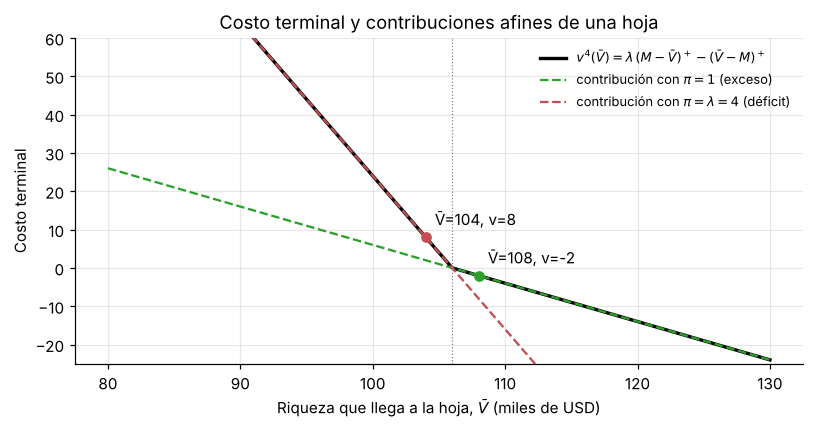

In [7]:
V = np.linspace(80, 130, 400)
cost = np.where(V < M_GOAL, LAM * (M_GOAL - V), -(V - M_GOAL))
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(V, cost, color="black", lw=2.2, label=r"$v^4(\bar V) = \lambda\,(M-\bar V)^+ - (\bar V - M)^+$")
ax.plot(V, 1 * (M_GOAL - V), ls="--", color="#2ca02c", label=r"contribución con $\pi = 1$ (exceso)")
ax.plot(V, LAM * (M_GOAL - V), ls="--", color="#c44e52", label=rf"contribución con $\pi = \lambda = {LAM:g}$ (déficit)")
for Vb, col in [(104, "#c44e52"), (108, "#2ca02c")]:
    vb = LAM * (M_GOAL - Vb) if Vb < M_GOAL else -(Vb - M_GOAL)
    ax.plot(Vb, vb, "o", color=col); ax.annotate(f"V̄={Vb}, v={vb:g}", (Vb, vb), textcoords="offset points", xytext=(6, 8))
ax.axvline(M_GOAL, color="gray", lw=0.8, ls=":")
ax.set_ylim(-25, 60)
ax.set_xlabel(r"Riqueza que llega a la hoja, $\bar V$ (miles de USD)")
ax.set_ylabel("Costo terminal")
ax.set_title("Costo terminal y contribuciones afines de una hoja")
ax.legend(frameon=False, fontsize=8.5)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "03_leaf_cost_and_cuts.png"); plt.show()

### 5.4 Recurso relativamente completo 

Para cualquier decisión factible del padre, todo nodo hijo tiene al menos una solución factible:

- **Nodos intermedios.** Si $\bar x^{t-1}_{a(k)} \ge 0$, la riqueza heredada es $\bar V = \hat R(u)^T \bar x \ge 0$ porque todos los factores son positivos. Entonces $x^t_k = (\bar V, 0, 0)$ es factible: no negativa y con suma $\bar V$. Cualquier riqueza disponible se puede repartir.
- **Hojas.** Para cualquier $\bar V$, la pareja $y = (\bar V - M)^+$, $w = (M - \bar V)^+$ es no negativa y cumple $\bar V - y + w = M$. Cualquier riqueza terminal se puede comparar con la meta, porque la meta no es una restricción dura.
- **Raíz.** $b = 100 > 0$, así que $x^1 = (b, 0, 0)$ es factible.

En consecuencia, ningún subproblema puede volverse infactible y no se necesitan cortes de factibilidad. Además, el costo es acotado inferiormente: el costo terminal cumple $\lambda w - y \ge M - V^4_k$ (porque $\lambda \ge 1$) y $V^4_k \le b R_{\max}^3$, lo que da la cota $L$ con la que el notebook 04 inicializará cada $\theta$. La celda siguiente lo comprueba numéricamente: desde decisiones extremas del padre (todo en un activo) y en cada rama, los LP hijos son factibles.

In [8]:
checked = 0
for u in ACTIVE_STATES:
    for i in range(N_ASSETS):
        x_bar = np.zeros(N_ASSETS); x_bar[i] = B_CAP
        V_bar = float(R_HAT[u] @ x_bar)
        r_mid = linprog(np.zeros(N_ASSETS), A_eq=np.ones((1, N_ASSETS)), b_eq=[V_bar],
                        bounds=(0, None), method="highs")
        r_leaf = linprog([-1.0, LAM], A_eq=[[-1.0, 1.0]], b_eq=[M_GOAL - V_bar], bounds=(0, None), method="highs")
        assert r_mid.status == 0 and r_leaf.status == 0
        checked += 2
print(f"✔ {checked} LP hijos (intermedios y terminales) factibles desde decisiones extremas del padre.")
print(f"  Cota del costo terminal: L = min(0, M − b·R_max³) = {params['L_theta_lower_bound']:.6f}")

✔ 48 LP hijos (intermedios y terminales) factibles desde decisiones extremas del padre.
  Cota del costo terminal: L = min(0, M − b·R_max³) = -38.221687


## 6. Instancia reducida de dos estados 

**Elección de los estados:** Se eligen **AAA** (los tres activos no bajan) y **BBB** (los tres bajan), porque representan los dos extremos del mercado y son fáciles de interpretar. La elección se fija antes de resolver y se puede cambiar en `REDUCED_STATES`; el notebook verifica que ambos estados estén presentes en los datos.

Se conservan sus factores $\hat R(u)$ y se renormalizan sus probabilidades,
$$\tilde q_u = \frac{\hat q_u}{\hat q_{\text{AAA}} + \hat q_{\text{BBB}}},$$
manteniendo los tres períodos. El árbol tiene $1 + 2 + 4 + 8 = 15$ nodos, $3 \cdot 7 + 2 \cdot 8 = 37$ variables y 15 igualdades. Esta instancia sirve solo para verificar la implementación; no reemplaza el modelo de ocho estados que se usa en la validación de 2026.

In [9]:
REDUCED_STATES = ["AAA", "BBB"]
assert all(u in ACTIVE_STATES and params["states"][u]["n"] > 0 for u in REDUCED_STATES), \
    "Los estados reducidos deben estar presentes en los datos."

q_sum = sum(Q_HAT[u] for u in REDUCED_STATES)
Q_RED = {u: Q_HAT[u] / q_sum for u in REDUCED_STATES}
R_RED = {u: R_HAT[u] for u in REDUCED_STATES}

red_tree = build_tree(REDUCED_STATES, Q_RED, R_RED)
de_red = build_de(red_tree, B_CAP, M_GOAL, LAM)

info = pd.DataFrame({
    "n_u": [params["states"][u]["n"] for u in REDUCED_STATES],
    "q̂_u (original)": [Q_HAT[u] for u in REDUCED_STATES],
    "q̃_u (renormalizada)": [Q_RED[u] for u in REDUCED_STATES],
    **{f"R̂_{tk}(u)": [R_RED[u][i] for u in REDUCED_STATES] for i, tk in enumerate(TICKERS)},
}, index=pd.Index(REDUCED_STATES, name="estado"))
with pd.option_context("display.float_format", "{:.6f}".format):
    display(info)

assert len(red_tree) == 15 and de_red["A"].shape == (15, 37)
assert np.isclose(red_tree.loc[red_tree["is_leaf"], "p_cum"].sum(), 1.0)
print(f"Árbol reducido: {len(red_tree)} nodos · {de_red['A'].shape[1]} variables · "
      f"{de_red['A'].shape[0]} igualdades · Σ p⁴ = {red_tree.loc[red_tree['is_leaf'], 'p_cum'].sum():.15f}")

,n_u,q̂_u (original),q̃_u (renormalizada),R̂_SPY(u),R̂_LQD(u),R̂_GLD(u)
estado,,,,,,
AAA,31,0.484375,0.911765,1.070526,1.034144,1.065740
BBB,3,0.046875,0.088235,0.919115,0.935849,0.937469


Árbol reducido: 15 nodos · 37 variables · 15 igualdades · Σ p⁴ = 1.000000000000000


La estructura del sistema $A_{eq}$ reducido muestra la forma escalonada del problema multietapa: cada fila (nodo) solo involucra sus variables locales, a través de $W_t$, y las de su padre, a través de $T_{t-1,k}$.

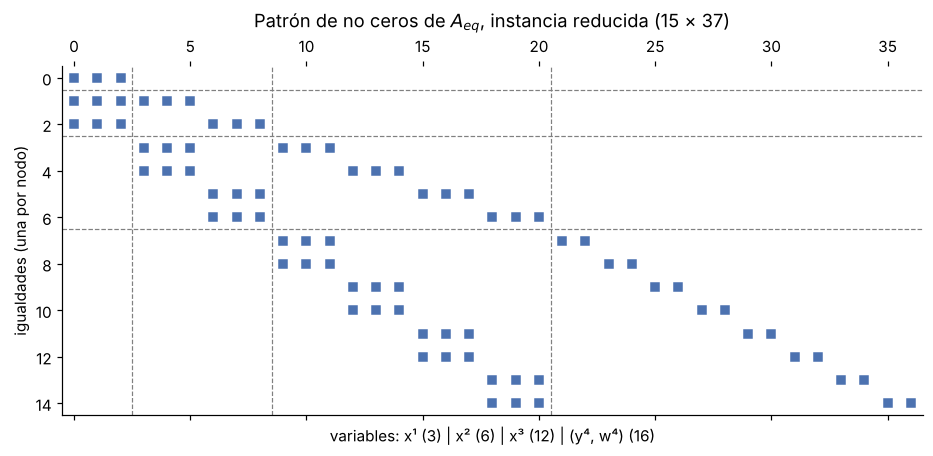

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.spy(de_red["A"].toarray(), markersize=5, color="#4c72b0")
bounds_ = np.cumsum([3, 3 * 2, 3 * 4])
for x in bounds_:
    ax.axvline(x - 0.5, color="gray", lw=0.8, ls="--")
for y_ in [0.5, 2.5, 6.5]:
    ax.axhline(y_, color="gray", lw=0.8, ls="--")
ax.set_xlabel("variables: x¹ (3) | x² (6) | x³ (12) | (y⁴, w⁴) (16)")
ax.set_ylabel("igualdades (una por nodo)")
ax.set_title("Patrón de no ceros de $A_{eq}$, instancia reducida (15 × 37)")
ax.grid(False)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "03_reduced_Aeq_sparsity.png"); plt.show()

## 7. Equivalente determinista de la instancia reducida

Se resuelve el LP completo de 37 variables y se verifica la solución de cuatro maneras independientes:

1. **Factibilidad:** residuo de las igualdades y no negatividad.
2. **Reevaluación de la política:** se propaga la riqueza por el árbol con las inversiones obtenidas, se calcula el costo de cada hoja como $\lambda (M - V)^+ - (V - M)^+$ y se compara el costo esperado con el valor óptimo del LP.
3. **Dualidad fuerte:** $b_{eq}^T \pi$ debe coincidir con el valor óptimo.
4. **Signo del dual del sistema:** se perturba el capital $b$ y se compara la variación del óptimo con el multiplicador de la igualdad de la raíz.

In [11]:
def extract_policy(de, x):
    tree = de["tree"]; rows = []
    for n in tree.itertuples():
        s = de["start"][(n.t, n.k)]
        if n.is_leaf:
            continue
        xv = x[s:s + N_ASSETS]; V = xv.sum()
        rows.append({"t": n.t, "k": n.k, "history": n.history, "p_cum": n.p_cum, "V": V,
                     **{f"x_{tk}": xv[i] for i, tk in enumerate(TICKERS)},
                     **{f"f_{tk}": xv[i] / V for i, tk in enumerate(TICKERS)}})
    return pd.DataFrame(rows)


def evaluate_policy(tree, x_by_node):
    # Propaga la riqueza con los factores de rama y calcula el costo de cada hoja.
    idx = tree.set_index(["t", "k"])
    out = []
    for n in tree[tree["is_leaf"]].itertuples():
        Rb = np.array([getattr(n, f"R_branch_{tk}") for tk in TICKERS])
        V4 = float(Rb @ x_by_node[(H - 1, int(n.parent_k))])
        y, w = max(V4 - M_GOAL, 0.0), max(M_GOAL - V4, 0.0)
        out.append({"k": n.k, "history": n.history, "p_cum": n.p_cum, "V4": V4,
                    "excess": y, "deficit": w, "cost": LAM * w - y})
    leaves = pd.DataFrame(out)
    return leaves, float((leaves["p_cum"] * leaves["cost"]).sum())


def verify_solution(de, res, label):
    x = res.x
    checks = []
    resid = np.max(np.abs(de["A"] @ x - de["b_eq"]))
    assert resid < 1e-8 and x.min() > -1e-9
    checks.append(f"factibilidad: residuo máx. {resid:.1e}, mínimo de las variables {x.min():.1e}")

    pol = extract_policy(de, x)
    x_by_node = {(r.t, r.k): np.array([getattr(r, f"x_{tk}") for tk in TICKERS]) for r in pol.itertuples()}
    # balances internos: la riqueza de cada nodo coincide con el valor heredado del padre
    idx = de["tree"].set_index(["t", "k"])
    for r in pol.itertuples():
        if r.t > 1:
            n = idx.loc[(r.t, r.k)]
            Rb = np.array([n[f"R_branch_{tk}"] for tk in TICKERS])
            assert abs(Rb @ x_by_node[(r.t - 1, int(n["parent_k"]))] - r.V) < 1e-7
    leaves, exp_cost = evaluate_policy(de["tree"], x_by_node)
    assert abs(exp_cost - res.fun) <= 1e-6 * max(1, abs(res.fun))
    checks.append(f"reevaluación de la política en las hojas: {exp_cost:.10f} = LP {res.fun:.10f}")

    pi = res.eqlin.marginals
    dual_obj = float(de["b_eq"] @ pi)
    assert abs(dual_obj - res.fun) <= 1e-6 * max(1, abs(res.fun))
    checks.append(f"dualidad fuerte: b_eqᵀπ = {dual_obj:.10f}")

    d = 1e-4
    de_p = dict(de); de_p["b_eq"] = de["b_eq"].copy(); de_p["b_eq"][0] += d
    fd = (solve_de(de_p)[0].fun - res.fun) / d
    assert abs(fd - pi[0]) < 1e-3 * max(1, abs(pi[0])), f"{label}: el signo del dual de la raíz no coincide."
    checks.append(f"signo del dual de la raíz: π¹ = {pi[0]:.8f}, diferencia finita = {fd:.8f}")
    return pol, leaves, pi, checks


res_red, t_red = solve_de(de_red)
pol_red, leaves_red, pi_red, checks_red = verify_solution(de_red, res_red, "reducida")
print(f"Óptimo del equivalente determinista reducido: {res_red.fun:.10f}   (tiempo {t_red * 1000:.1f} ms)")
for c in checks_red:
    print("  ✔", c)

Óptimo del equivalente determinista reducido: -10.8024277068   (tiempo 4.2 ms)
  ✔ factibilidad: residuo máx. 4.5e-13, mínimo de las variables 0.0e+00
  ✔ reevaluación de la política en las hojas: -10.8024277068 = LP -10.8024277068
  ✔ dualidad fuerte: b_eqᵀπ = -10.8024277068
  ✔ signo del dual de la raíz: π¹ = -1.70469156, diferencia finita = -1.70469156


In [12]:
print("Política óptima de la instancia reducida (montos en miles de USD y proporciones):")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(pol_red.set_index(["t", "k"]))
print("Hojas de la instancia reducida:")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(leaves_red.set_index("k"))
print(f"Riqueza esperada: {(leaves_red['p_cum'] * leaves_red['V4']).sum():.4f} · "
      f"déficit esperado: {(leaves_red['p_cum'] * leaves_red['deficit']).sum():.4f}")

Política óptima de la instancia reducida (montos en miles de USD y proporciones):


history  p_cum        V   x_SPY  x_LQD   x_GLD  f_SPY  f_LQD  f_GLD
t k                                                                     
1 1     raíz 1.0000 100.0000 68.2875 0.0000 31.7125 0.6829 0.0000 0.3171
2 1      AAA 0.9118 106.9009 65.3517 0.0000 41.5492 0.6113 0.0000 0.3887
  2      BBB 0.0882  92.4935 92.4935 0.0000  0.0000 1.0000 0.0000 0.0000
3 1  AAA|AAA 0.8313 114.2413 59.8042 0.0000 54.4371 0.5235 0.0000 0.4765
  2  AAA|BBB 0.0804  99.0167 99.0167 0.0000  0.0000 1.0000 0.0000 0.0000
  3  BBB|AAA 0.0804  99.0167 99.0167 0.0000  0.0000 1.0000 0.0000 0.0000
  4  BBB|BBB 0.0078  85.0121 85.0121 0.0000  0.0000 1.0000 0.0000 0.0000

Hojas de la instancia reducida:


,history,p_cum,V4,excess,deficit,cost
k,,,,,,
1,AAA|AAA|AAA,0.7580,122.0378,16.0378,0.0000,-16.0378
2,AAA|AAA|BBB,0.0734,106.0000,0.0000,0.0000,0.0000
3,AAA|BBB|AAA,0.0734,106.0000,0.0000,0.0000,-0.0000
4,AAA|BBB|BBB,0.0071,91.0077,0.0000,14.9923,59.9691
5,BBB|AAA|AAA,0.0734,106.0000,0.0000,0.0000,-0.0000
6,BBB|AAA|BBB,0.0071,91.0077,0.0000,14.9923,59.9691
7,BBB|BBB|AAA,0.0071,91.0077,0.0000,14.9923,59.9691
8,BBB|BBB|BBB,0.0007,78.1359,0.0000,27.8641,111.4564


Riqueza esperada: 117.8177 · déficit esperado: 0.3384


In [13]:
for a in TICKERS:
    ia = TICKERS.index(a)
    if all(R_RED[u][ia] >= R_RED[u].max() - 1e-15 for u in REDUCED_STATES):
        print(f"En los estados {REDUCED_STATES}, {a} tiene el mayor factor en ambos: "
              "domina a los otros activos en esta instancia.")
        break
else:
    print(f"Ningún activo domina a los demás en los estados {REDUCED_STATES}.")

Ningún activo domina a los demás en los estados ['AAA', 'BBB'].


## 8. Equivalente determinista del caso completo (comparación adicional)

Resolver el problema completo del árbol de ocho combinaciones no es obligatorio, porque la solución oficial del caso completo es la que entrega el L-shaped anidado con sus pasadas, cortes y cotas. Aun así, con 1 243 variables y 585 restricciones el problema se resuelve en milisegundos, así que se calcula aquí y se guarda para contrastarlo con el L-shaped en el notebook 04. Es solo una referencia: la política que se usa en los notebooks 05 y 06 es la del L-shaped.

In [14]:
SOLVE_FULL_DE = True

if SOLVE_FULL_DE:
    res_full, t_full = solve_de(de_full)
    pol_full, leaves_full, pi_full, checks_full = verify_solution(de_full, res_full, "completa")
    print(f"Óptimo del equivalente determinista completo: {res_full.fun:.10f}   (tiempo {t_full * 1000:.1f} ms)")
    for c in checks_full:
        print("  ✔", c)
    root = pol_full.iloc[0]
    print("Raíz:", ", ".join(f"{tk} {root[f'f_{tk}']:.2%}" for tk in TICKERS))

Óptimo del equivalente determinista completo: 1.2711985137   (tiempo 17.4 ms)
  ✔ factibilidad: residuo máx. 3.2e-12, mínimo de las variables 0.0e+00
  ✔ reevaluación de la política en las hojas: 1.2711985137 = LP 1.2711985137
  ✔ dualidad fuerte: b_eqᵀπ = 1.2711985137
  ✔ signo del dual de la raíz: π¹ = -1.97874499, diferencia finita = -1.97874499
Raíz: SPY 84.23%, LQD 0.00%, GLD 15.77%


## 9. Exportación

Se guardan el árbol reducido, la solución del equivalente reducido (referencia obligatoria para el notebook 04) y, si se resolvió, la del equivalente completo, cada una con los hashes de las entradas.

In [15]:
def save_solution(folder, prefix, de, res, elapsed, pol, leaves, pi, checks, extra):
    pol.to_csv(folder / f"{prefix}_policy.csv", index=False, float_format="%.12g")
    leaves.to_csv(folder / f"{prefix}_leaves.csv", index=False, float_format="%.12g")
    sol = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "calibration_parameters_sha256": params_hash,
        "solver": f"scipy.optimize.linprog(method='highs'), scipy {scipy.__version__}",
        "n_variables": int(de["A"].shape[1]), "n_equalities": int(de["A"].shape[0]),
        "objective": float(res.fun), "solve_time_s": elapsed,
        "variables": dict(zip(de["names"], map(float, res.x))),
        "duals_by_node_id": list(map(float, pi)),
        "checks_passed": checks, **extra,
    }
    path = folder / f"{prefix}_solution.json"
    path.write_text(json.dumps(sol, indent=2, ensure_ascii=False), encoding="utf-8")
    return path

red_tree.to_csv(REDUCED_DIR / "reduced_tree_nodes.csv", index=False, float_format="%.15g")
p_red = save_solution(REDUCED_DIR, "reduced_de", de_red, res_red, t_red, pol_red, leaves_red, pi_red, checks_red,
                      {"role": "Referencia para verificar L-shaped anidado (sección 4.1)",
                       "reduced_states": REDUCED_STATES, "q_renormalized": Q_RED})
saved = [REDUCED_DIR / "reduced_tree_nodes.csv", p_red, REDUCED_DIR / "reduced_de_policy.csv",
         REDUCED_DIR / "reduced_de_leaves.csv"]
if SOLVE_FULL_DE:
    p_full = save_solution(FULL_DE_DIR, "full_de", de_full, res_full, t_full, pol_full, leaves_full, pi_full,
                           checks_full, {"role": "Comparación adicional; no sustituye L-shaped (sección 4.1)",
                                         "tree_csv_sha256": tree_meta["csv_sha256"]})
    saved += [p_full, FULL_DE_DIR / "full_de_policy.csv", FULL_DE_DIR / "full_de_leaves.csv"]
saved += [FIGURES_DIR / "03_leaf_cost_and_cuts.png", FIGURES_DIR / "03_reduced_Aeq_sparsity.png"]
print("Guardado:")
for p in saved:
    print("  ", p.relative_to(ROOT))

Guardado:
   results/reduced/reduced_tree_nodes.csv
   results/reduced/reduced_de_solution.json
   results/reduced/reduced_de_policy.csv
   results/reduced/reduced_de_leaves.csv
   results/full_de/full_de_solution.json
   results/full_de/full_de_policy.csv
   results/full_de/full_de_leaves.csv
   results/figures/03_leaf_cost_and_cuts.png
   results/figures/03_reduced_Aeq_sparsity.png
